# Teste exato de McNemar aplicado ao programa *Safe Fall*

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RodrigoSantosB/mcnemar-safe-fall/blob/main/notebooks/01_mcnemar_safe_fall.ipynb)

> **No Colab:** use *Ambiente de execução → Executar tudo*. A primeira célula de código clona o repositório e carrega os módulos; nada mais precisa ser instalado. Os controles interativos aparecem na **Etapa 9a** e na **Etapa 12** (todos os exemplos dos slides).

**Artigo:** DelCastillo-Andrés, Ó. *et al.* (2018). *Children's Improvement of a Motor Response during Backward Falls through the Implementation of a Safe Fall Program.* Int. J. Environ. Res. Public Health 15, 2669. [doi:10.3390/ijerph15122669](https://doi.org/10.3390/ijerph15122669) (CC BY 4.0)

Este notebook separa três tipos de dado com rótulos explícitos:

| Rótulo | O que é |
|---|---|
| 🟥 **PUBLICADO** | Valores transcritos da Tabela 1 do artigo, sem correção |
| 🟧 **INFERIDO** | Tabelas 2×2 deduzidas algebricamente das margens + X² publicados (hipótese testada na Etapa 2) |
| 🟦 **SINTÉTICO** | Exemplos didáticos gerados por nós (educação, demonstração interativa) |

O código reutilizável está em `src/safe_fall_statistics/`; o notebook só orquestra as etapas.

In [1]:
# Configuração: funciona localmente (clone do repositório) e no Google Colab
import sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/RodrigoSantosB/mcnemar-safe-fall.git"

def find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "pyproject.toml").exists() and (p / "src" / "safe_fall_statistics").exists():
            return p
    return None

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT = find_root()
if ROOT is None:  # Colab ou notebook aberto fora do repositório: baixa o código
    target = Path("/content/mcnemar-safe-fall") if IN_COLAB else Path.cwd() / "mcnemar-safe-fall"
    if not target.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q", REPO_URL, str(target)], check=True)
    ROOT = target
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

if IN_COLAB:  # widgets interativos no Colab
    from google.colab import output
    output.enable_custom_widget_manager()

import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from safe_fall_statistics import visualizations as viz
from safe_fall_statistics.contingency_tables import PairedTable
from safe_fall_statistics.data_loader import load_published_table1, N_TOTAL, SOURCE
from safe_fall_statistics.data_validation import audit_table1, check_row_totals
from safe_fall_statistics.mcnemar_analysis import (
    mcnemar_exact, exact_pvalue_manual, compare_methods, format_p, interpret, binomial_null_pmf,
    odds_ratio_discordant,
)
from safe_fall_statistics.reconstruction import reconstruct_table1, reconstructed_tables, feasible_range
from safe_fall_statistics.synthetic_data import (
    EDUCATION_EXAMPLE, EXACT_VS_ASYMPTOTIC, individuals_from_table, SYNTHETIC_LABEL,
)
pd.set_option("display.precision", 4)
print("Código carregado de", ROOT, "| Colab:", IN_COLAB)

Código carregado de /home/rsb6/Desktop/projeto estatistica | Colab: False


## Etapa 1 — Introdução

**Questão de pesquisa do artigo:** a resposta motora de escolares de 10–12 anos numa queda para trás muda depois do programa *Safe Fall*?

Cada criança foi observada **duas vezes** (pré e pós) e, em cada comportamento, classificada como **correta** ou **incorreta** (escala INFOSECA). Temos portanto:

* **amostras pareadas** — as mesmas 122 crianças nos dois momentos;
* **variável dicotômica** — correto / incorreto.

O **teste de McNemar** responde: *a proporção de respostas corretas mudou?* Ele faz isso olhando apenas para quem **mudou de categoria** — e comparando quantos melhoraram com quantos pioraram.

## Etapa 2 — Dados

### 2a. 🟥 Dados publicados (Tabela 1)

In [2]:
t1 = load_published_table1()
print(SOURCE)
t1

DelCastillo-Andrés et al. (2018), Int. J. Environ. Res. Public Health 15:2669, Tabela 1. doi:10.3390/ijerph15122669 (CC BY 4.0)


,variable_en,variavel_pt,pre_correct_n,pre_correct_pct_reported,pre_incorrect_n,pre_incorrect_pct_reported,post_correct_n,post_correct_pct_reported,post_incorrect_n,post_incorrect_pct_reported,chi2_reported,p_reported
0,Bending the neck,Flexão do pescoço,28,23.6,94,76.4,110,90.2,12,9.8,76.291,0.0
1,Not using hands,Não apoiar as mãos,1,1.6,121,98.4,107,90.2,15,9.8,104.009,0.0
2,Rolling up,Enrolamento corporal,9,8.1,113,91.9,111,91.1,11,8.9,96.236,0.0
3,Bending hip,Flexão do quadril,1,1.6,121,98.4,106,87.0,16,13.0,103.010,0.0
4,Bending knees,Flexão dos joelhos,68,56.1,54,43.9,116,95.1,6,4.9,42.481,0.0


### 2b. Auditoria da Tabela 1

As contagens somam 122 em todas as linhas. Recalculamos cada porcentagem como `n / 122` e comparamos com a impressa; tolerância = meia unidade da casa decimal impressa.

In [3]:
print("Totais pré e pós = 122:", check_row_totals(t1).all())
audit = audit_table1(t1)
audit[audit.divergente]

Totais pré e pós = 122: True


,variavel,celula,n,pct_publicada,pct_recalculada,diferenca_pp,divergente
0,Flexão do pescoço,pre_correct,28,23.6,22.95,0.65,True
1,Flexão do pescoço,pre_incorrect,94,76.4,77.05,-0.65,True
4,Não apoiar as mãos,pre_correct,1,1.6,0.82,0.78,True
5,Não apoiar as mãos,pre_incorrect,121,98.4,99.18,-0.78,True
6,Não apoiar as mãos,post_correct,107,90.2,87.70,2.50,True
7,Não apoiar as mãos,post_incorrect,15,9.8,12.30,-2.50,True
8,Enrolamento corporal,pre_correct,9,8.1,7.38,0.72,True
9,Enrolamento corporal,pre_incorrect,113,91.9,92.62,-0.72,True
10,Enrolamento corporal,post_correct,111,91.1,90.98,0.12,True
11,Enrolamento corporal,post_incorrect,11,8.9,9.02,-0.12,True


**Leitura da auditoria (nada foi corrigido):**

* **Pré-teste**: as porcentagens de quatro variáveis não correspondem a `n/122` (ex.: pescoço 28 → impresso 23,6 %, recalculado 22,95 %; mãos e quadril 1 → impresso 1,6 %, recalculado 0,82 %). O próprio texto do artigo diz "0,8 %" para o quadril, compatível com a contagem.
* **Não apoiar as mãos, pós-teste**: 107 (impresso 90,2 %) e 15 (impresso 9,8 %). O correto seria 87,7 % e 12,3 %; os valores impressos são idênticos aos da linha do pescoço — provável erro de cópia, repetido no texto ("fell to 9.8 %").
* **Enrolamento, pós-teste**: 111 → impresso 91,1 %, recalculado 90,98 % (diferença pequena).
* A coluna *p* é impressa como `0.000`: isso é arredondamento — o correto é **p < 0,001**, nunca "p = 0".

Usaremos sempre as **contagens**, que são internamente consistentes.

### 2c. As margens não bastam

A Tabela 1 dá, para cada variável, apenas os totais pré e pós (margens). O McNemar precisa de `b` e `c` — e muitas tabelas diferentes têm as mesmas margens. As margens fixam somente a **diferença** `c − b = (pós correto) − (pré correto)`, **não** a soma `b + c`.

In [4]:
lo, hi = feasible_range(pre_correct=28, post_correct=110)
print(f"Flexão do pescoço: qualquer b entre {lo} e {hi} é compatível com as margens 28 → 110")
rows = []
for b in [lo, 5, 10, hi]:
    c = b + 82
    t = PairedTable(28 - b, b, c, 94 - c)
    rows.append({"b": b, "c": c, "a": t.a, "d": t.d, "p exato": mcnemar_exact(t).pvalue})
pd.DataFrame(rows)

Flexão do pescoço: qualquer b entre 0 e 12 é compatível com as margens 28 → 110


,b,c,a,d,p exato
0,0,82,28,12,4.1359e-25
1,5,87,23,7,2.1043e-20
2,10,92,18,2,9.3995e-18
3,12,94,16,0,6.1981e-17


### 2d. 🟧 Inferência das tabelas 2×2 a partir do X² publicado

Porém a tabela também publica um **X²**. Se ele for o qui-quadrado de McNemar **com correção de continuidade** (o que o SPSS reporta), então

$$X^2 = \frac{(|c-b|-1)^2}{b+c} \;\Rightarrow\; b+c = \frac{(|c-b|-1)^2}{X^2}.$$

Como `c − b` vem das margens, `b + c` — e portanto `b` e `c` — ficam determinados. A hipótese é **falsificável**: `b + c` precisa sair inteiro, as células precisam ser não negativas e o X² recalculado precisa bater nas 3 casas decimais.

In [5]:
rec_cc = reconstruct_table1(t1, correction=True)
rec_nc = reconstruct_table1(t1, correction=False)
display(Markdown("**Hipótese: X² com correção de continuidade** — " + rec_cc.attrs["status"]))
display(rec_cc)
display(Markdown("**Hipótese alternativa: X² sem correção**"))
display(rec_nc[["variavel", "b+c (bruto)", "viavel"]])

**Hipótese: X² com correção de continuidade** — INFERIDO — não é dado original do artigo

,variavel,b+c (bruto),viavel,a,b,c,d,X2_publicado,X2_recalculado
0,Flexão do pescoço,85.9997,True,26,2,84,10,76.291,76.291
1,Não apoiar as mãos,106.0004,True,1,0,106,15,104.009,104.009
2,Enrolamento corporal,105.9998,True,7,2,104,9,96.236,96.236
3,Flexão do quadril,104.9995,True,1,0,105,16,103.010,103.010
4,Flexão dos joelhos,51.9997,True,66,2,50,4,42.481,42.481


**Hipótese alternativa: X² sem correção**

,variavel,b+c (bruto),viavel
0,Flexão do pescoço,88.1362,False
1,Não apoiar as mãos,108.0291,False
2,Enrolamento corporal,108.1092,False
3,Flexão do quadril,107.0284,False
4,Flexão dos joelhos,54.2360,False


Com correção de continuidade, `b + c` sai **exatamente inteiro nas cinco variáveis** e o X² é reproduzido até a 3ª casa decimal; sem correção, nenhuma linha fecha. Isso é forte evidência de que o X² da tabela é o McNemar corrigido — e permite inferir as tabelas 2×2.

> ⚠️ Estas tabelas são **inferidas**, não publicadas. Se o X² tivesse sido calculado de outra forma, a inferência não valeria. Os microdados individuais não estão disponíveis.

In [6]:
tables = reconstructed_tables(t1)
for name, t in tables.items():
    print(f"{name:22s}  a={t.a:3d}  b={t.b:3d}  c={t.c:3d}  d={t.d:3d}   (pré correto {t.pre_correct}, pós correto {t.post_correct})")

Flexão do pescoço       a= 26  b=  2  c= 84  d= 10   (pré correto 28, pós correto 110)
Não apoiar as mãos      a=  1  b=  0  c=106  d= 15   (pré correto 1, pós correto 107)
Enrolamento corporal    a=  7  b=  2  c=104  d=  9   (pré correto 9, pós correto 111)
Flexão do quadril       a=  1  b=  0  c=105  d= 16   (pré correto 1, pós correto 106)
Flexão dos joelhos      a= 66  b=  2  c= 50  d=  4   (pré correto 68, pós correto 116)


### 2e. 🟦 Dados sintéticos — exemplo em educação

Uma escola aplica a mesma questão a 40 alunos antes e depois de uma aula de reforço. Geramos os **microdados individuais** (um aluno por linha) com semente fixa.

In [7]:
edu = individuals_from_table(EDUCATION_EXAMPLE, seed=2018, id_prefix="AL")
print(edu.attrs["status"])
edu.head(8)

SINTÉTICO — exemplo didático, não é dado do estudo


,id,pre,pos
0,AL001,1,1
1,AL002,0,0
2,AL003,0,1
3,AL004,0,0
4,AL005,0,0
5,AL006,0,1
6,AL007,0,1
7,AL008,1,1


## Etapa 3 — Análise exploratória

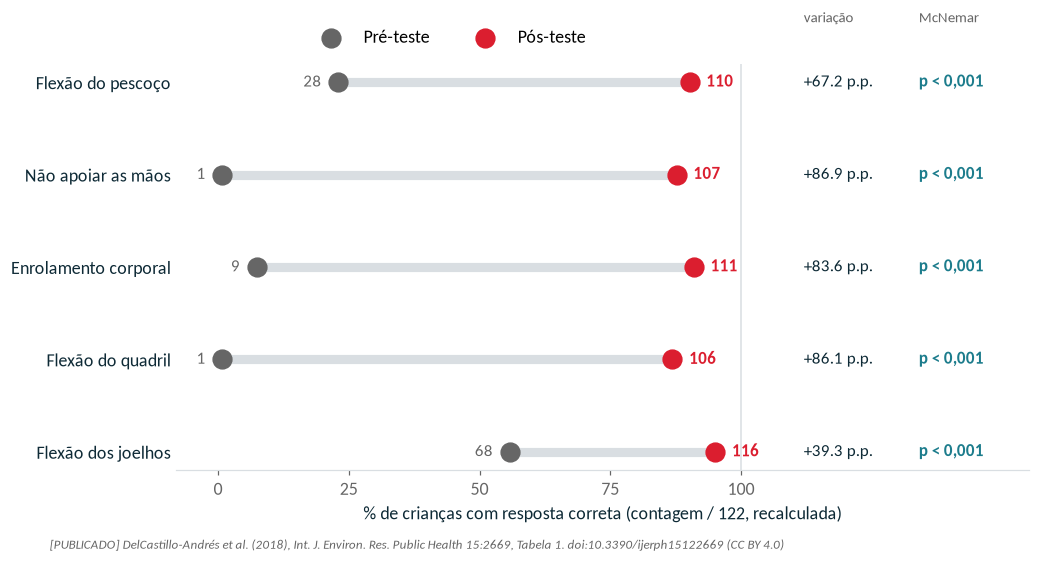

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
viz.plot_pre_post(t1, ax=ax, source="[PUBLICADO] " + SOURCE)
plt.show()

**Gráfico interativo (Plotly)** — passe o mouse para ver contagens e porcentagens recalculadas.

In [9]:
import plotly.graph_objects as go

pct = lambda n: 100 * n / N_TOTAL
fig = go.Figure()
fig.add_bar(name="Pré-teste", x=t1.variavel_pt, y=pct(t1.pre_correct_n), marker_color=viz.GRAY,
            customdata=t1.pre_correct_n, hovertemplate="%{x}<br>pré: %{customdata}/122 = %{y:.1f}%<extra></extra>")
fig.add_bar(name="Pós-teste", x=t1.variavel_pt, y=pct(t1.post_correct_n), marker_color=viz.RED,
            customdata=t1.post_correct_n, hovertemplate="%{x}<br>pós: %{customdata}/122 = %{y:.1f}%<extra></extra>")
fig.update_layout(barmode="group", template="simple_white", yaxis_title="% corretas", height=420,
                  title="🟥 PUBLICADO — respostas corretas antes e depois do Safe Fall (n = 122)")
fig.show()

In [10]:
print("Exemplo de educação (🟦 SINTÉTICO):")
pd.crosstab(edu.pre.map({1: "Acertou", 0: "Errou"}), edu.pos.map({1: "Acertou", 0: "Errou"}),
            rownames=["Pré"], colnames=["Pós"], margins=True)

Exemplo de educação (🟦 SINTÉTICO):


Pós,Acertou,Errou,All
Pré,,,
Acertou,15,3,18
Errou,13,9,22
All,28,12,40


## Etapa 4 — Construção da tabela 2 × 2

|  | Pós: correto | Pós: incorreto |
|---|---:|---:|
| **Pré: correto** | *a* (permaneceu correto) | ***b*** (piorou) |
| **Pré: incorreto** | ***c*** (melhorou) | *d* (permaneceu incorreto) |

`b` e `c` são os **pares discordantes**. `a` e `d` (concordantes) **não entram** na estatística.

In [11]:
t_edu = PairedTable.from_paired(edu.pre, edu.pos)
display(t_edu.to_frame())
display(t_edu.transitions())
print("Total preservado:", t_edu.n, "| discordantes b + c =", t_edu.discordant)

,Pós: correto,Pós: incorreto
Pré: correto,15,3
Pré: incorreto,13,9


,transicao,celula,n,tipo
0,Correto → correto,a,15,concordante
1,Correto → incorreto,b,3,discordante
2,Incorreto → correto,c,13,discordante
3,Incorreto → incorreto,d,9,concordante


Total preservado: 40 | discordantes b + c = 16


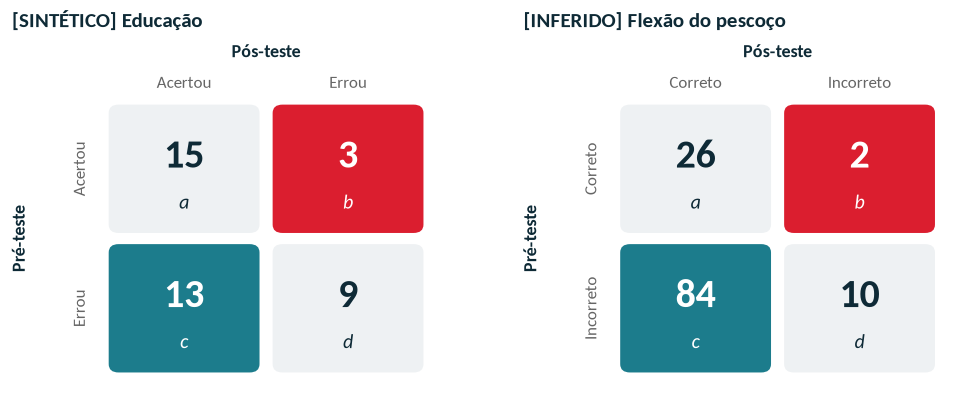

In [12]:
neck = tables["Flexão do pescoço"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
viz.plot_contingency(t_edu, ax=axes[0], title="[SINTÉTICO] Educação", labels=("Acertou", "Errou"))
viz.plot_contingency(neck, ax=axes[1], title="[INFERIDO] Flexão do pescoço")
plt.show()

## Etapa 5 — Hipóteses

Seja $p_b$ a probabilidade de um indivíduo passar de correto para incorreto e $p_c$ a de passar de incorreto para correto.

* **H₀:** $p_b = p_c$ — mudanças nos dois sentidos são igualmente prováveis. Equivale à **homogeneidade marginal**: $P(\text{correto no pré}) = P(\text{correto no pós})$, pois $p_{\text{pré}} - p_{\text{pós}} = p_b - p_c$.
* **H₁:** $p_b \neq p_c$ (bilateral).
* **α = 0,05**, como no artigo.

## Etapa 6 — Cálculo manual do p-valor exato

Condicionando aos $n = b + c$ pares discordantes, sob H₀ cada um é "piorou" com probabilidade ½:

$$B \sim \text{Binomial}(n,\ 0{,}5), \qquad p = \min\Big(1,\ 2\sum_{k=0}^{\min(b,c)} \binom{n}{k} 0{,}5^{\,n}\Big).$$

Como a distribuição é simétrica, dobrar a cauda menor equivale a somar todas as probabilidades $\le P(B=b_{\text{obs}})$.

**Exemplo de educação:** b = 3, c = 13, n = 16.

In [13]:
from math import comb
b, c = t_edu.b, t_edu.c
n = b + c
terms = [comb(n, k) for k in range(min(b, c) + 1)]
tail = sum(terms) / 2**n
print(f"P(B ≤ {min(b, c)}) = ({' + '.join(map(str, terms))}) / 2^{n} = {sum(terms)}/{2**n} = {tail:.6f}")
print(f"p exato bilateral = 2 × {tail:.6f} = {2 * tail:.6f}")
print("função do projeto  :", exact_pvalue_manual(b, c))

P(B ≤ 3) = (1 + 16 + 120 + 560) / 2^16 = 697/65536 = 0.010635
p exato bilateral = 2 × 0.010635 = 0.021271
função do projeto  : 0.021270751953125


## Etapa 7 — Implementação com bibliotecas

`statsmodels.stats.contingency_tables.mcnemar(exact=True)` e validação independente com `scipy.stats.binomtest`.

In [14]:
from statsmodels.stats.contingency_tables import mcnemar
from scipy.stats import binomtest

result = mcnemar(t_edu.to_array(), exact=True)
print("statsmodels  estatística =", result.statistic, "  p =", result.pvalue)
print("scipy        p =", binomtest(b, n, 0.5, alternative="two-sided").pvalue)
print("manual       p =", exact_pvalue_manual(b, c))

statsmodels  estatística = 3.0   p = 0.021270751953125
scipy        p = 0.021270751953125
manual       p = 0.021270751953125


In [15]:
rows = []
for name, t in {"Educação (🟦 sintético)": t_edu, **{f"{k} (🟧 inferido)": v for k, v in tables.items()}}.items():
    r = mcnemar_exact(t)
    rows.append({"caso": name, "b": t.b, "c": t.c, "b+c": t.discordant, "estatística min(b,c)": r.statistic,
                 "p statsmodels": r.pvalue, "p manual": r.pvalue_manual, "p scipy": r.pvalue_scipy,
                 "consistentes": r.consistent, "relato": format_p(r.pvalue), "razão c/b": odds_ratio_discordant(t)})
results = pd.DataFrame(rows)
results

,caso,b,c,b+c,"estatística min(b,c)",p statsmodels,p manual,p scipy,consistentes,relato,razão c/b
0,Educação (🟦 sintético),3,13,16,3.0,2.1271e-02,2.1271e-02,2.1271e-02,True,"p = 0,021",4.3333
1,Flexão do pescoço (🟧 inferido),2,84,86,2.0,9.6728e-23,9.6728e-23,9.6728e-23,True,"p < 0,001",42.0000
2,Não apoiar as mãos (🟧 inferido),0,106,106,0.0,2.4652e-32,2.4652e-32,2.4652e-32,True,"p < 0,001",inf
3,Enrolamento corporal (🟧 inferido),2,104,106,2.0,1.3983e-28,1.3983e-28,1.3983e-28,True,"p < 0,001",52.0000
4,Flexão do quadril (🟧 inferido),0,105,105,0.0,4.9304e-32,4.9304e-32,4.9304e-32,True,"p < 0,001",inf
5,Flexão dos joelhos (🟧 inferido),2,50,52,2.0,6.1240e-13,6.1240e-13,6.1240e-13,True,"p < 0,001",25.0000


In [16]:
assert results["consistentes"].all(), "Implementações divergiram!"
print("✔ manual, scipy e statsmodels concordam em todos os casos")

✔ manual, scipy e statsmodels concordam em todos os casos


## Etapa 8 — Exato × aproximação assintótica

A versão assintótica usa $\chi^2 = (|b-c| - k)^2/(b+c)$ com 1 g.l. ($k=0$ sem correção, $k=1$ com correção de Edwards). Com poucos pares discordantes, a aproximação pode **mudar a conclusão**.

In [17]:
pd.DataFrame([compare_methods(t) for t in [EXACT_VS_ASYMPTOTIC, t_edu, neck]],
             index=["🟦 b=1, c=7", "🟦 educação", "🟧 pescoço"])

,b,c,n_discordantes,p_exato,chi2_sem_correcao,p_chi2_sem_correcao,chi2_com_correcao,p_chi2_com_correcao
"🟦 b=1, c=7",1,7,8,7.0312e-02,4.500,3.3895e-02,3.1250,7.7100e-02
🟦 educação,3,13,16,2.1271e-02,6.250,1.2419e-02,5.0625,2.4449e-02
🟧 pescoço,2,84,86,9.6728e-23,78.186,9.3779e-19,76.2907,2.4483e-18


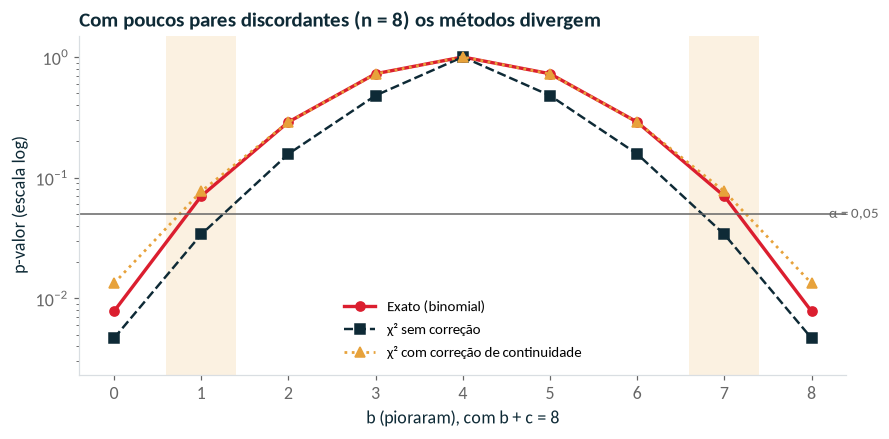

In [18]:
fig, ax = plt.subplots(figsize=(9, 4))
viz.plot_exact_vs_asymptotic(n=8, ax=ax)
plt.show()

Em **b = 1, c = 7** o χ² sem correção dá p ≈ 0,034 (rejeita H₀), enquanto o exato dá p ≈ 0,070 (não rejeita). Com dezenas de pares discordantes — como no Safe Fall — os três métodos concordam.

**Regra prática:** com $b + c$ pequeno (frequentemente se cita < 25) use o exato; ele é sempre válido.

## Etapa 9 — Visualização

### 9a. 🎛️ Demonstração interativa — *Como o McNemar funciona?*

Mova `c` (melhoraram) e `b` (pioraram). Observe que `a` e `d` alteram a tabela, mas **não** o p-valor.

> Se os controles não aparecerem (ex.: visualização estática no GitHub), rode `render(b, c)` na célula seguinte.

In [19]:
from safe_fall_statistics.interactive_demo import mcnemar_widget, render
mcnemar_widget(b=3, c=13, a=15, d=9)

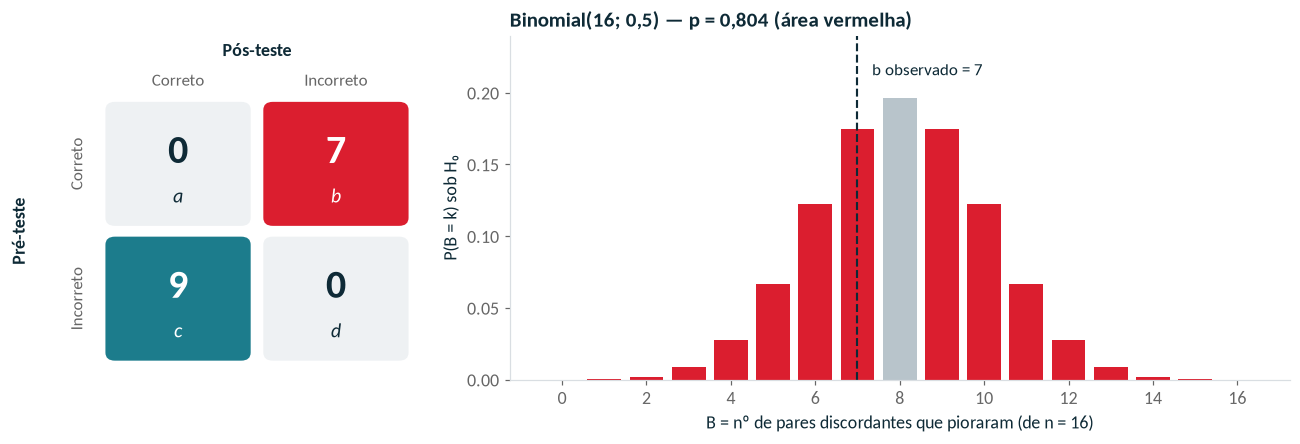

Pares discordantes: b + c = 16   |   estatística exata min(b,c) = 7   |   p exato = 0.8036
Entre os 16 pares discordantes, 9 melhoraram e 7 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 8,0 em cada sentido. p = 0,804. Não rejeitamos H0 ao nível de 5%: os dados são compatíveis com ausência de mudança.


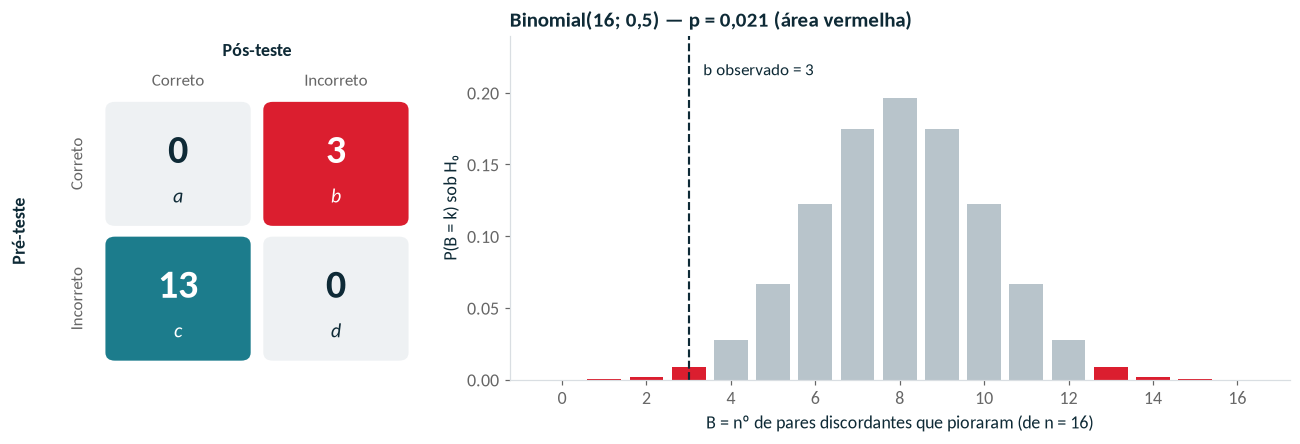

Pares discordantes: b + c = 16   |   estatística exata min(b,c) = 3   |   p exato = 0.02127
Entre os 16 pares discordantes, 13 melhoraram e 3 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 8,0 em cada sentido. p = 0,021. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.


In [20]:
# Versão estática: equilibrado × desequilibrado com o mesmo n = 16
for b_, c_ in [(7, 9), (3, 13)]:
    render(b_, c_)

### 9b. Pares discordantes no Safe Fall (🟧 inferido)

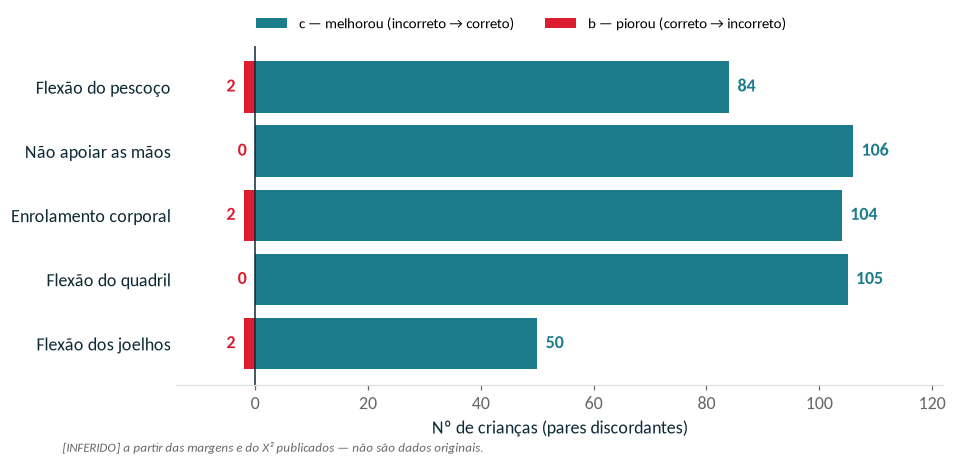

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
viz.plot_discordant_bars(tables, ax=ax, note="[INFERIDO] a partir das margens e do X² publicados — não são dados originais.")
plt.show()

### 9c. Fluxo de transições pré → pós

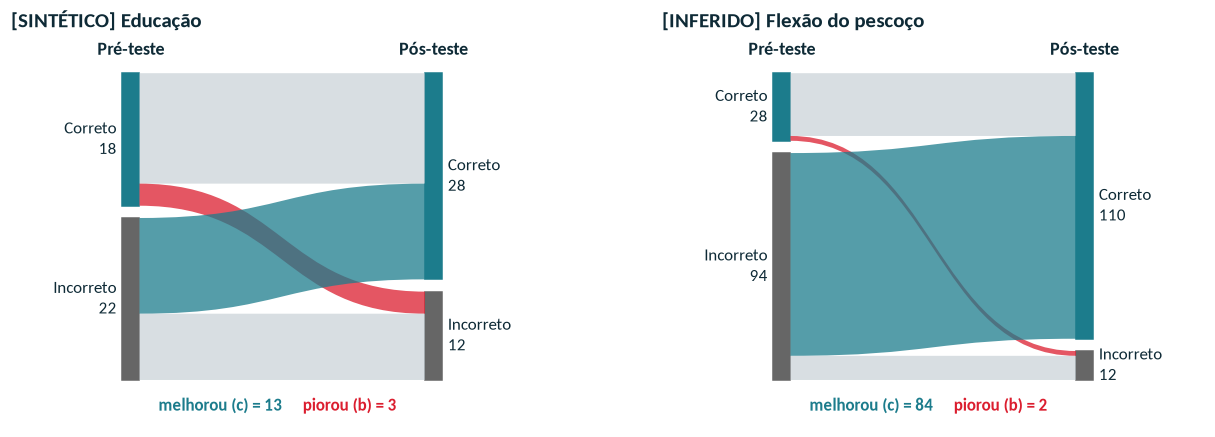

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
viz.plot_transitions(t_edu, ax=axes[0], title="[SINTÉTICO] Educação")
viz.plot_transitions(neck, ax=axes[1], title="[INFERIDO] Flexão do pescoço")
plt.show()

In [23]:
def sankey(t, title):
    labels = ["Pré: correto", "Pré: incorreto", "Pós: correto", "Pós: incorreto"]
    link_colors = ["rgba(184,196,203,.6)", "rgba(219,30,47,.7)", "rgba(28,124,140,.7)", "rgba(184,196,203,.6)"]
    f = go.Figure(go.Sankey(
        node=dict(label=labels, color=[viz.TEAL, viz.GRAY, viz.TEAL, viz.GRAY], pad=18),
        link=dict(source=[0, 0, 1, 1], target=[2, 3, 2, 3], value=[t.a, t.b, t.c, t.d], color=link_colors,
                  customdata=["a: permaneceu correto", "b: piorou", "c: melhorou", "d: permaneceu incorreto"],
                  hovertemplate="%{customdata}: %{value}<extra></extra>")))
    f.update_layout(title=title, height=360, font_size=13)
    return f

sankey(neck, "🟧 Flexão do pescoço — transições inferidas").show()

### 9d. Distribuição sob H₀ para o pescoço (🟧 inferido)

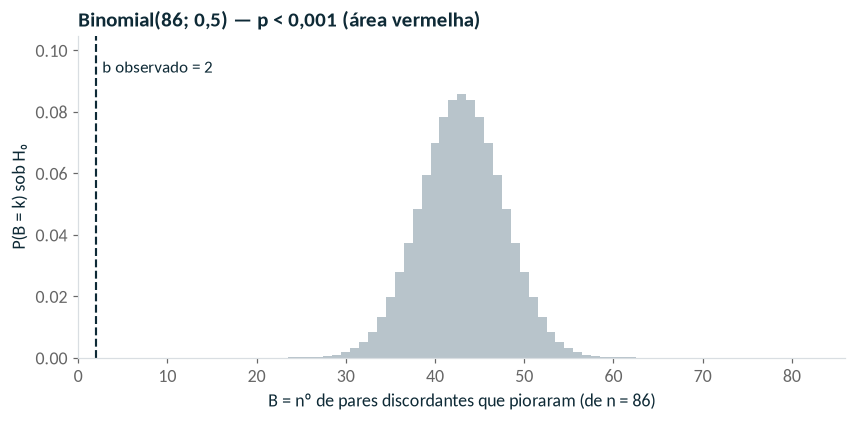

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.8))
viz.plot_binomial_null(neck.b, neck.c, ax=ax)
plt.show()

## Etapa 10 — Interpretação

In [25]:
r_edu = mcnemar_exact(t_edu)
display(Markdown("**🟦 Educação (sintético):** " + interpret(r_edu)))
for name, t in tables.items():
    display(Markdown(f"**🟧 {name} (inferido):** " + interpret(mcnemar_exact(t))))

**🟦 Educação (sintético):** Entre os 16 pares discordantes, 13 melhoraram e 3 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 8,0 em cada sentido. p = 0,021. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.

**🟧 Flexão do pescoço (inferido):** Entre os 86 pares discordantes, 84 melhoraram e 2 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 43,0 em cada sentido. p < 0,001. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.

**🟧 Não apoiar as mãos (inferido):** Entre os 106 pares discordantes, 106 melhoraram e 0 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 53,0 em cada sentido. p < 0,001. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.

**🟧 Enrolamento corporal (inferido):** Entre os 106 pares discordantes, 104 melhoraram e 2 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 53,0 em cada sentido. p < 0,001. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.

**🟧 Flexão do quadril (inferido):** Entre os 105 pares discordantes, 105 melhoraram e 0 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 52,5 em cada sentido. p < 0,001. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.

**🟧 Flexão dos joelhos (inferido):** Entre os 52 pares discordantes, 50 melhoraram e 2 pioraram — mais indivíduos melhoraram do que pioraram, Sob H0 esperaríamos 26,0 em cada sentido. p < 0,001. Rejeitamos H0 ao nível de 5%: a proporção de acertos mudou entre pré e pós.

**Linguagem estatística.** Para cada comportamento rejeitamos H₀ (p < 0,001): a proporção de crianças com resposta correta no pós-teste difere da do pré-teste.

**Linguagem aplicada.** Depois do programa, muito mais crianças passaram a executar a resposta protetora do que deixaram de executá-la (ex.: pescoço, 84 contra 2).

**Cuidados:**

* *Significância ≠ tamanho do efeito.* Relate também a mudança em pontos percentuais (+67 p.p. no pescoço) e a razão c/b.
* *Significância ≠ causalidade.* Sem grupo controle, parte da mudança pode vir de familiaridade com o teste (no pós a queda é mais previsível), maturação ou expectativa do avaliador.
* *Comportamento ≠ lesão.* O desfecho foi a resposta motora em ambiente controlado; o estudo não mediu lesões.

## Etapa 11 — Comparação com o artigo

In [26]:
cmp = t1[["variavel_pt", "chi2_reported", "p_reported"]].rename(columns={"variavel_pt": "variavel"}).copy()
cmp["p publicado (texto)"] = "0.000 → p < 0,001"
cmp["b (🟧)"] = [tables[v].b for v in cmp.variavel]
cmp["c (🟧)"] = [tables[v].c for v in cmp.variavel]
cmp["χ² corrigido recalculado"] = [compare_methods(tables[v])["chi2_com_correcao"] for v in cmp.variavel]
cmp["p exato (🟧)"] = [mcnemar_exact(tables[v]).pvalue for v in cmp.variavel]
cmp["relato"] = [format_p(p) for p in cmp["p exato (🟧)"]]
cmp

,variavel,chi2_reported,p_reported,p publicado (texto),b (🟧),c (🟧),χ² corrigido recalculado,p exato (🟧),relato
0,Flexão do pescoço,76.291,0.0,"0.000 → p < 0,001",2,84,76.2907,9.6728e-23,"p < 0,001"
1,Não apoiar as mãos,104.009,0.0,"0.000 → p < 0,001",0,106,104.0094,2.4652e-32,"p < 0,001"
2,Enrolamento corporal,96.236,0.0,"0.000 → p < 0,001",2,104,96.2358,1.3983e-28,"p < 0,001"
3,Flexão do quadril,103.010,0.0,"0.000 → p < 0,001",0,105,103.0095,4.9304e-32,"p < 0,001"
4,Flexão dos joelhos,42.481,0.0,"0.000 → p < 0,001",2,50,42.4808,6.1240e-13,"p < 0,001"


| Aspecto | Artigo | Este notebook |
|---|---|---|
| Teste | "McNemar's exact test", SPSS 24, α = 0,05 | Exato via statsmodels, validado por scipy e cálculo manual |
| Estatística relatada | Coluna X² (= McNemar com correção de continuidade, conforme a inferência) | Exato: min(b, c); χ² apenas para comparação |
| p-valor | Impresso `0.000` | p < 0,001 (exatos entre ~10⁻³² e ~10⁻¹²) |
| Tabelas 2×2 | Não publicadas | 🟧 Inferidas; não verificáveis sem microdados |
| Conclusão | Mudança significativa nas 5 respostas | Mesma conclusão — robusta a qualquer dos três métodos |

**Limites da reprodução:** sem os dados individuais não dá para confirmar as tabelas inferidas nem refazer outras análises citadas (correlações, teste t por sexo). As porcentagens inconsistentes da Tabela 1 não afetam o teste, que depende só das contagens.

## Etapa 12 — Exemplos dos slides, ajustáveis

Cada aba reproduz um exemplo da apresentação com os mesmos valores iniciais; mova os controles para explorar.

| Aba | Slide | O que ajustar |
|---|---|---|
| passo a passo | 8 | b e c — o cálculo manual é refeito linha a linha |
| sig. × não sig. | 9 | dois cenários (b, c) lado a lado |
| exato × χ² | 10 | n = b + c e b — mostra quando os métodos discordam |
| Safe Fall | 18 | comportamento e b — começa na tabela INFERIDA; outros b mantêm as margens publicadas |
| demonstração | 22 | a, b, c, d |
| p-valor × c | 23 | n e c |
| educação | 24 | a, b, c, d (SINTÉTICO) |

Os gráficos só são redesenhados quando você solta o controle, o que mantém o Colab responsivo.

In [27]:
from safe_fall_statistics.slide_examples import slide_examples_widget
slide_examples_widget()